<a href="https://colab.research.google.com/github/tejashwinijeevangi/Real-time-face-mask-detection-system-/blob/main/DL_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!pip install tensorflow keras opencv-python numpy imutils scikit-learn

In [ ]:
# 1. Install Libraries
!pip install tensorflow keras opencv-python numpy imutils scikit-learn

# 2. Mount Google Drive (Try the standard command first)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 🚨 CHANGE 'YourProjectFolder' to the exact name you uploaded (e.g., 'FaceMaskProject')
BASE_PATH = "/content/drive/MyDrive/FaceMaskProject"

# Define Paths for assets
DATASET_DIR = os.path.join(BASE_PATH, "dataset")
FACE_MODEL_PROTO = os.path.join(BASE_PATH, "face_detector", "deploy.prototxt")
FACE_MODEL_CAFFE = os.path.join(BASE_PATH, "face_detector", "res10_300x300_ssd_iter_140000.caffemodel")
OUTPUT_MODEL_PATH = os.path.join(BASE_PATH, "mask_detector.h5")

# Quick verification: This MUST print True for the next step to work!
print(f"Dataset path being checked: {DATASET_DIR}")
print(f"Does the dataset folder exist? {os.path.isdir(DATASET_DIR)}")

Dataset path being checked: /content/drive/MyDrive/FaceMaskProject/dataset
Does the dataset folder exist? True


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import AveragePooling2D, Dropout, Flatten, Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input # Ensure preprocess_input is here
from tensorflow.keras.preprocessing.image import img_to_array # Ensure img_to_array is here
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
from imutils import paths
import numpy as np
import cv2
import os

# NOTE: The BASE_PATH and other asset variables (DATASET_DIR, OUTPUT_MODEL_PATH)
# must be defined in the previous cell!

# --- Model Parameters ---
INIT_LR = 1e-4
EPOCHS = 20
BS = 32
CATEGORIES = ["with_mask", "without_mask"]

# --- 3.1 Load and Pre-process Data ---
print("[INFO] Loading images...")
data = []
labels = []

for category in CATEGORIES:
    path = os.path.join(DATASET_DIR, category)
    # Since the previous step was True, we proceed to load files
    for imgPath in list(paths.list_images(path)):
        # Load and preprocess image
        image = cv2.imread(imgPath)
        if image is None: # Skip if image loading failed
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (224, 224))
        image = img_to_array(image)
        image = preprocess_input(image) # MobileNetV2 specific preprocessing

        data.append(image)
        labels.append(category)

# Convert to arrays and split
if len(data) == 0:
    print("[FATAL ERROR] No images were loaded. Please double check the file paths.")
else:
    data = np.array(data, dtype="float32")
    labels = np.array(labels)

    lb = LabelBinarizer()
    labels = lb.fit_transform(labels)
    labels = to_categorical(labels)

    (trainX, testX, trainY, testY) = train_test_split(data, labels, test_size=0.20, stratify=labels, random_state=42)

    # --- 3.2 Data Augmentation ---
    aug = ImageDataGenerator(rotation_range=20, zoom_range=0.15, width_shift_range=0.2, height_shift_range=0.2,
        shear_range=0.15, horizontal_flip=True, fill_mode="nearest")

    # --- 3.3 Build and Compile Model ---
    # Load MobileNetV2 base model with pre-trained ImageNet weights
    baseModel = MobileNetV2(weights="imagenet", include_top=False, input_tensor=Input(shape=(224, 224, 3)))

    # Construct the classification head
    headModel = baseModel.output
    headModel = AveragePooling2D(pool_size=(7, 7))(headModel)
    headModel = Flatten(name="flatten")(headModel)
    headModel = Dense(128, activation="relu")(headModel)
    headModel = Dropout(0.5)(headModel)
    headModel = Dense(len(CATEGORIES), activation="softmax")(headModel)

    # Combine the base model and the new head
    model = Model(inputs=baseModel.input, outputs=headModel)

    # Freeze the base layers so only the new head layers are trained
    for layer in baseModel.layers:
        layer.trainable = False

    opt = Adam(learning_rate=INIT_LR)
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])

    # --- 3.4 Train Model (FIXED SECTION) ---
    print("[INFO] Training head...")

    # Run the fit function with corrected arguments
    H = model.fit(
        # Flow for training data
        aug.flow(trainX, trainY, batch_size=BS),
        steps_per_epoch=len(trainX) // BS,

        # Use the validation data tuple directly without separate flow()
        validation_data=(testX, testY),
        # Remove validation_steps as it's often incompatible when validation_data is a tuple
        epochs=EPOCHS)

    # --- 3.5 Save Model ---
    print("[INFO] Saving mask detector model...")
    model.save(OUTPUT_MODEL_PATH, save_format="h5")
    print(f"[INFO] Model saved to: {OUTPUT_MODEL_PATH}")

[INFO] Loading images...


/tmp/ipython-input-3957835147.py:67: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  baseModel = MobileNetV2(weights="imagenet", include_top=False, input_tensor=Input(shape=(224, 224, 3)))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[INFO] Training head...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 104s 568ms/step - accuracy: 0.7993 - loss: 0.4538 - val_accuracy: 0.9733 - val_loss: 0.0837
Epoch 2/20
  1/149 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.9062 - loss: 0.1443

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9062 - loss: 0.1443 - val_accuracy: 0.9733 - val_loss: 0.0834
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 53s 356ms/step - accuracy: 0.9674 - loss: 0.1135 - val_accuracy: 0.9792 - val_loss: 0.0583
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9688 - loss: 0.0960 - val_accuracy: 0.9792 - val_loss: 0.0582
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 53s 356ms/step - accuracy: 0.9718 - loss: 0.0811 - val_accuracy: 0.9833 - val_loss: 0.0510
Epoch 6/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9688 - loss: 0.0888 - val_accuracy: 0.9833 - val_loss: 0.0511
Epoch 7/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 80s 355ms/step - accuracy: 0.9755 - loss: 0.0729 - val_accuracy: 0.9850 - val_loss: 0.0455
Epoch 8/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 1.0000 - loss: 0.0130 - val_accuracy: 0.9850 - val_loss: 0.0456
Epoch 9/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 53s 358ms/step - accuracy: 0.9780 - loss: 0.0665 - val_accuracy: 

[INFO] Saving mask detector model...
[INFO] Model saved to: /content/drive/MyDrive/FaceMaskProject/mask_detector.h5



--- Starting Live Camera Snapshot Demo ---


<IPython.core.display.Javascript object>

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step

--- Final Result ---


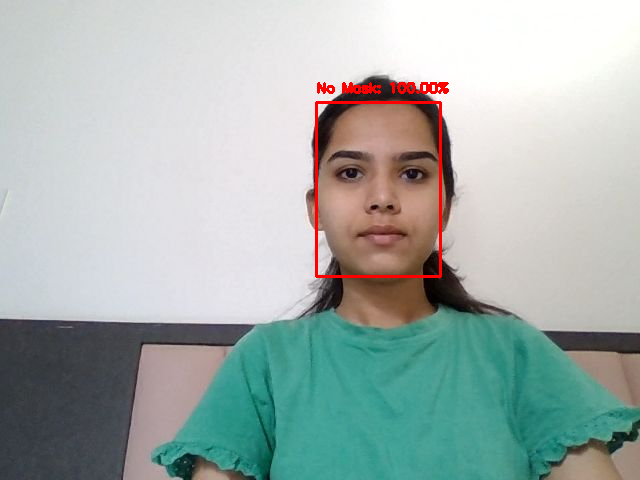

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import io
from PIL import Image
from google.colab.patches import cv2_imshow # For displaying the final output
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
import os

# NOTE: The asset paths (FACE_MODEL_CAFFE, OUTPUT_MODEL_PATH, etc.)
# are carried over from your previous successful cells.

# --- 4.1 Define Webcam Capture Function (Colab Utility) ---
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
          const div = document.createElement('div');
          const capture = document.createElement('button');
          capture.textContent = 'Capture Frame';
          div.appendChild(capture);

          const video = document.createElement('video');
          video.style.display = 'block';
          const stream = await navigator.mediaDevices.getUserMedia({video: true});

          document.body.appendChild(div);
          div.appendChild(video);
          video.srcObject = stream;
          await video.play();

          // Resize the output to fit the video element.
          google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

          // Wait for the capture button to be clicked.
          await new Promise((resolve) => capture.onclick = resolve);

          const canvas = document.createElement('canvas');
          canvas.width = video.videoWidth;
          canvas.height = video.videoHeight;
          canvas.getContext('2d').drawImage(video, 0, 0);
          stream.getVideoTracks()[0].stop();
          div.remove();
          return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    # Convert binary data to an OpenCV image format (numpy array)
    img = Image.open(io.BytesIO(binary))
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

# --- 4.2 Define Detection and Prediction Function ---
def detect_and_predict_mask(frame, faceNet, maskNet):
    (h, w) = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(frame, 1.0, (300, 300), (104.0, 177.0, 123.0))

    faceNet.setInput(blob)
    detections = faceNet.forward()

    faces = []
    locs = []

    for i in range(0, detections.shape[2]):
        confidence = detections[0, 0, i, 2]

        if confidence > 0.5:
            box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
            (startX, startY, endX, endY) = box.astype("int")

            (startX, startY) = (max(0, startX), max(0, startY))
            (endX, endY) = (min(w - 1, endX), min(h - 1, endY))

            face = frame[startY:endY, startX:endX]
            if face.any():
              face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
              face = cv2.resize(face, (224, 224))
              face = img_to_array(face)
              face = preprocess_input(face)

              faces.append(face)
              locs.append((startX, startY, endX, endY))

    preds = []
    if len(faces) > 0:
        faces = np.array(faces, dtype="float32")
        preds = maskNet.predict(faces, batch_size=32)

    return (locs, preds)

# --- 4.3 Load Models for Demo and Execute ---
try:
    # Use the asset variables defined in your previous path cell
    FACE_MODEL_CAFFE = os.path.join(BASE_PATH, "face_detector", "res10_300x300_ssd_iter_140000.caffemodel")
    FACE_MODEL_PROTO = os.path.join(BASE_PATH, "face_detector", "deploy.prototxt")
    OUTPUT_MODEL_PATH = os.path.join(BASE_PATH, "mask_detector.h5")

    faceNet = cv2.dnn.readNet(FACE_MODEL_CAFFE, FACE_MODEL_PROTO)
    maskNet = tf.keras.models.load_model(OUTPUT_MODEL_PATH)
except Exception as e:
    print(f"Error loading models. Did the model save correctly? Error: {e}")
    faceNet = None
    maskNet = None

if faceNet and maskNet:
    print("\n--- Starting Live Camera Snapshot Demo ---")
    try:
        # 1. Capture a frame from the webcam (browser will ask for permission)
        frame = take_photo()

        # 2. Run the mask detection logic
        (locs, preds) = detect_and_predict_mask(frame, faceNet, maskNet)

        # 3. Draw the boxes and labels
        for (box, pred) in zip(locs, preds):
            (startX, startY, endX, endY) = box
            idx = np.argmax(pred)
            label = "Mask" if idx == 0 else "No Mask"
            color = (0, 255, 0) if label == "Mask" else (0, 0, 255) # Green/Red

            label_text = f"{label}: {pred[idx] * 100:.2f}%"

            cv2.putText(frame, label_text, (startX, startY - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 2)
            cv2.rectangle(frame, (startX, startY), (endX, endY), color, 2)

        # 4. Display the final result
        print("\n--- Final Result ---")
        cv2_imshow(frame)
    except Exception as e:
        print(f"An error occurred during webcam capture or processing. Ensure your webcam is available: {e}")


--- Starting Live Camera Snapshot Demo ---


<IPython.core.display.Javascript object>

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step

--- Final Result ---


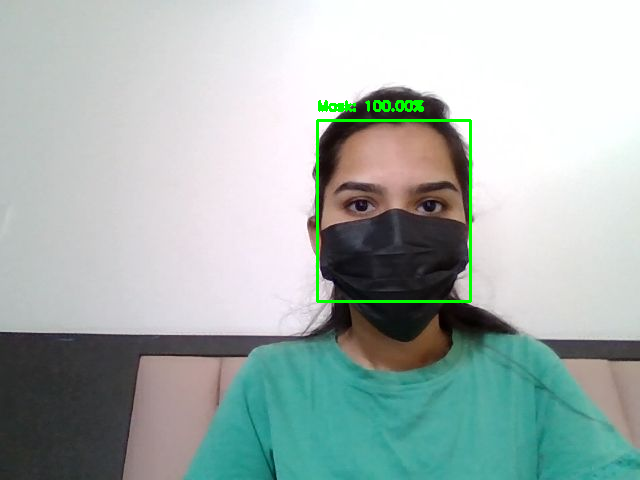

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import io
from PIL import Image
from google.colab.patches import cv2_imshow # For displaying the final output
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
import os

# NOTE: The asset paths (FACE_MODEL_CAFFE, OUTPUT_MODEL_PATH, etc.)
# are carried over from your previous successful cells.

# --- 4.1 Define Webcam Capture Function (Colab Utility) ---
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
          const div = document.createElement('div');
          const capture = document.createElement('button');
          capture.textContent = 'Capture Frame';
          div.appendChild(capture);

          const video = document.createElement('video');
          video.style.display = 'block';
          const stream = await navigator.mediaDevices.getUserMedia({video: true});

          document.body.appendChild(div);
          div.appendChild(video);
          video.srcObject = stream;
          await video.play();

          // Resize the output to fit the video element.
          google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

          // Wait for the capture button to be clicked.
          await new Promise((resolve) => capture.onclick = resolve);

          const canvas = document.createElement('canvas');
          canvas.width = video.videoWidth;
          canvas.height = video.videoHeight;
          canvas.getContext('2d').drawImage(video, 0, 0);
          stream.getVideoTracks()[0].stop();
          div.remove();
          return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    # Convert binary data to an OpenCV image format (numpy array)
    img = Image.open(io.BytesIO(binary))
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

# --- 4.2 Define Detection and Prediction Function ---
def detect_and_predict_mask(frame, faceNet, maskNet):
    (h, w) = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(frame, 1.0, (300, 300), (104.0, 177.0, 123.0))

    faceNet.setInput(blob)
    detections = faceNet.forward()

    faces = []
    locs = []

    for i in range(0, detections.shape[2]):
        confidence = detections[0, 0, i, 2]

        if confidence > 0.5:
            box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
            (startX, startY, endX, endY) = box.astype("int")

            (startX, startY) = (max(0, startX), max(0, startY))
            (endX, endY) = (min(w - 1, endX), min(h - 1, endY))

            face = frame[startY:endY, startX:endX]
            if face.any():
              face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
              face = cv2.resize(face, (224, 224))
              face = img_to_array(face)
              face = preprocess_input(face)

              faces.append(face)
              locs.append((startX, startY, endX, endY))

    preds = []
    if len(faces) > 0:
        faces = np.array(faces, dtype="float32")
        preds = maskNet.predict(faces, batch_size=32)

    return (locs, preds)

# --- 4.3 Load Models for Demo and Execute ---
try:
    # Use the asset variables defined in your previous path cell
    FACE_MODEL_CAFFE = os.path.join(BASE_PATH, "face_detector", "res10_300x300_ssd_iter_140000.caffemodel")
    FACE_MODEL_PROTO = os.path.join(BASE_PATH, "face_detector", "deploy.prototxt")
    OUTPUT_MODEL_PATH = os.path.join(BASE_PATH, "mask_detector.h5")

    faceNet = cv2.dnn.readNet(FACE_MODEL_CAFFE, FACE_MODEL_PROTO)
    maskNet = tf.keras.models.load_model(OUTPUT_MODEL_PATH)
except Exception as e:
    print(f"Error loading models. Did the model save correctly? Error: {e}")
    faceNet = None
    maskNet = None

if faceNet and maskNet:
    print("\n--- Starting Live Camera Snapshot Demo ---")
    try:
        # 1. Capture a frame from the webcam (browser will ask for permission)
        frame = take_photo()

        # 2. Run the mask detection logic
        (locs, preds) = detect_and_predict_mask(frame, faceNet, maskNet)

        # 3. Draw the boxes and labels
        for (box, pred) in zip(locs, preds):
            (startX, startY, endX, endY) = box
            idx = np.argmax(pred)
            label = "Mask" if idx == 0 else "No Mask"
            color = (0, 255, 0) if label == "Mask" else (0, 0, 255) # Green/Red

            label_text = f"{label}: {pred[idx] * 100:.2f}%"

            cv2.putText(frame, label_text, (startX, startY - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 2)
            cv2.rectangle(frame, (startX, startY), (endX, endY), color, 2)

        # 4. Display the final result
        print("\n--- Final Result ---")
        cv2_imshow(frame)
    except Exception as e:
        print(f"An error occurred during webcam capture or processing. Ensure your webcam is available: {e}")

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import io
from PIL import Image
from google.colab.patches import cv2_imshow # For displaying the final output
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
import os

# NOTE: The asset paths (FACE_MODEL_CAFFE, OUTPUT_MODEL_PATH, etc.)
# are carried over from your previous successful cells.

# --- 4.1 Define Webcam Capture Function (Colab Utility) ---
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
          const div = document.createElement('div');
          const capture = document.createElement('button');
          capture.textContent = 'Capture Frame';
          div.appendChild(capture);

          const video = document.createElement('video');
          video.style.display = 'block';
          const stream = await navigator.mediaDevices.getUserMedia({video: true});

          document.body.appendChild(div);
          div.appendChild(video);
          video.srcObject = stream;
          await video.play();

          // Resize the output to fit the video element.
          google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

          // Wait for the capture button to be clicked.
          await new Promise((resolve) => capture.onclick = resolve);

          const canvas = document.createElement('canvas');
          canvas.width = video.videoWidth;
          canvas.height = video.videoHeight;
          canvas.getContext('2d').drawImage(video, 0, 0);
          stream.getVideoTracks()[0].stop();
          div.remove();
          return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    # Convert binary data to an OpenCV image format (numpy array)
    img = Image.open(io.BytesIO(binary))
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

# --- 4.2 Define Detection and Prediction Function ---
def detect_and_predict_mask(frame, faceNet, maskNet):
    (h, w) = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(frame, 1.0, (300, 300), (104.0, 177.0, 123.0))

    faceNet.setInput(blob)
    detections = faceNet.forward()

    faces = []
    locs = []

    for i in range(0, detections.shape[2]):
        confidence = detections[0, 0, i, 2]

        if confidence > 0.5:
            box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
            (startX, startY, endX, endY) = box.astype("int")

            (startX, startY) = (max(0, startX), max(0, startY))
            (endX, endY) = (min(w - 1, endX), min(h - 1, endY))

            face = frame[startY:endY, startX:endX]
            if face.any():
              face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
              face = cv2.resize(face, (224, 224))
              face = img_to_array(face)
              face = preprocess_input(face)

              faces.append(face)
              locs.append((startX, startY, endX, endY))

    preds = []
    if len(faces) > 0:
        faces = np.array(faces, dtype="float32")
        preds = maskNet.predict(faces, batch_size=32)

    return (locs, preds)

# --- 4.3 Load Models for Demo and Execute ---
try:
    # Use the asset variables defined in your previous path cell
    FACE_MODEL_CAFFE = os.path.join(BASE_PATH, "face_detector", "res10_300x300_ssd_iter_140000.caffemodel")
    FACE_MODEL_PROTO = os.path.join(BASE_PATH, "face_detector", "deploy.prototxt")
    OUTPUT_MODEL_PATH = os.path.join(BASE_PATH, "mask_detector.h5")

    faceNet = cv2.dnn.readNet(FACE_MODEL_CAFFE, FACE_MODEL_PROTO)
    maskNet = tf.keras.models.load_model(OUTPUT_MODEL_PATH)
except Exception as e:
    print(f"Error loading models. Did the model save correctly? Error: {e}")
    faceNet = None
    maskNet = None

if faceNet and maskNet:
    print("\n--- Starting Live Camera Snapshot Demo ---")
    try:
        # 1. Capture a frame from the webcam (browser will ask for permission)
        frame = take_photo()

        # 2. Run the mask detection logic
        (locs, preds) = detect_and_predict_mask(frame, faceNet, maskNet)

        # 3. Draw the boxes and labels
        for (box, pred) in zip(locs, preds):
            (startX, startY, endX, endY) = box
            idx = np.argmax(pred)
            label = "Mask" if idx == 0 else "No Mask"
            color = (0, 255, 0) if label == "Mask" else (0, 0, 255) # Green/Red

            label_text = f"{label}: {pred[idx] * 100:.2f}%"

            cv2.putText(frame, label_text, (startX, startY - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 2)
            cv2.rectangle(frame, (startX, startY), (endX, endY), color, 2)

        # 4. Display the final result
        print("\n--- Final Result ---")
        cv2_imshow(frame)
    except Exception as e:
        print(f"An error occurred during webcam capture or processing. Ensure your webcam is available: {e}")

Error loading models. Did the model save correctly? Error: name 'BASE_PATH' is not defined
